# Glioma survival analysis — Step 2: EDA, Kaplan-Meier, Cox

Data: TCGA LGG+GBM (`src/prepare_data.py`) → `data/processed/glioma.csv`

* `time` = overall survival (months), `event` = 1 death / 0 censored
* Goal of this step: which clinical/molecular factors separate survival, before any ML model.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import multivariate_logrank_test
from lifelines.plotting import add_at_risk_counts

df = pd.read_csv("../data/processed/glioma.csv", index_col="patient_id")
print(df.shape)
df.head()

(1040, 13)


,age,histology,kps,time,sex,atrx,chr7_10,grade,subtype,idh,mgmt,tert,event
patient_id,,,,,,,,,,,,,
TCGA-02-0001,44.0,glioblastoma,80.0,11.8,Female,NaN,yes,4,IDHwt,WT,Unmethylated,NaN,1
TCGA-02-0003,50.0,glioblastoma,100.0,4.7,Male,WT,yes,4,IDHwt,WT,Unmethylated,NaN,1
TCGA-02-0004,59.0,glioblastoma,80.0,11.3,Male,NaN,NaN,4,NaN,WT,NaN,NaN,1
TCGA-02-0006,56.0,glioblastoma,80.0,18.3,Female,NaN,yes,4,IDHwt,WT,Unmethylated,NaN,1
TCGA-02-0007,40.0,glioblastoma,80.0,23.2,Female,NaN,no,4,IDHwt,WT,Unmethylated,NaN,1


## 1. Quick look
Censoring matters: ~half the patients are still alive at last follow-up, so we cannot simply average `time` — that is why we need survival methods.

event
died        524
censored    516
Name: count, dtype: int64

tert         0.69
kps          0.33
atrx         0.28
mgmt         0.18
subtype      0.13
idh          0.12
chr7_10      0.03
age          0.00
histology    0.00
time         0.00
sex          0.00
grade        0.00
event        0.00
dtype: float64


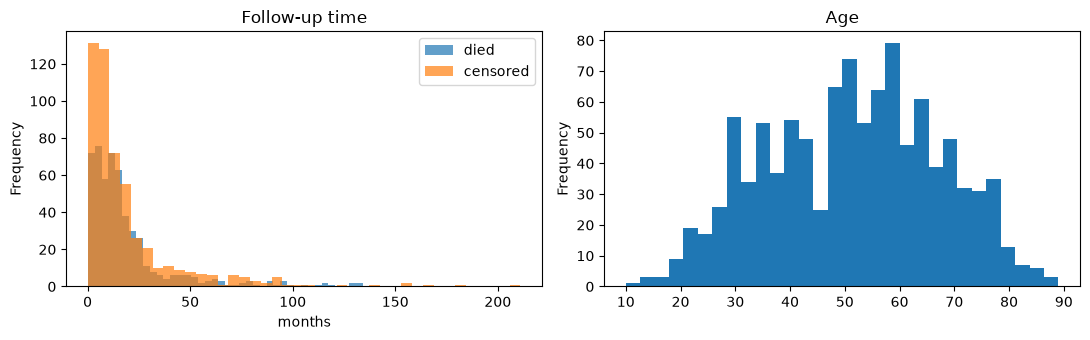

In [2]:
print(df["event"].value_counts().rename({1: "died", 0: "censored"}))
print()
print(df.isna().mean().round(2).sort_values(ascending=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df.loc[df.event == 1, "time"].plot.hist(bins=40, alpha=.7, ax=ax[0], label="died")
df.loc[df.event == 0, "time"].plot.hist(bins=40, alpha=.7, ax=ax[0], label="censored")
ax[0].set_xlabel("months"); ax[0].legend(); ax[0].set_title("Follow-up time")
df["age"].plot.hist(bins=30, ax=ax[1]); ax[1].set_title("Age")
plt.tight_layout()

## 2. Kaplan-Meier — whole cohort

median OS (months): 20.7


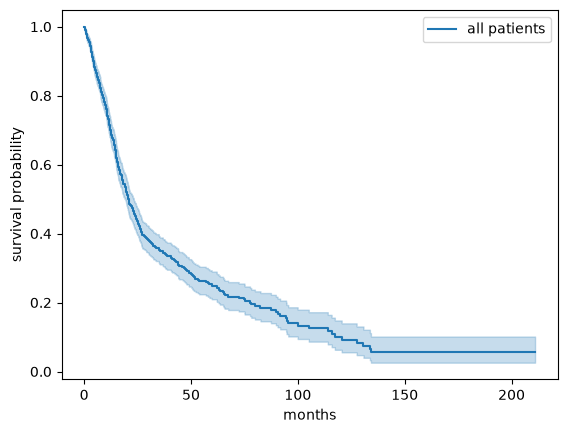

In [3]:
kmf = KaplanMeierFitter()
kmf.fit(df["time"], df["event"], label="all patients")
ax = kmf.plot_survival_function()
ax.set_xlabel("months"); ax.set_ylabel("survival probability")
print("median OS (months):", kmf.median_survival_time_)

## 3. Kaplan-Meier by group + log-rank test
Log-rank H0: all groups have the same survival curve.

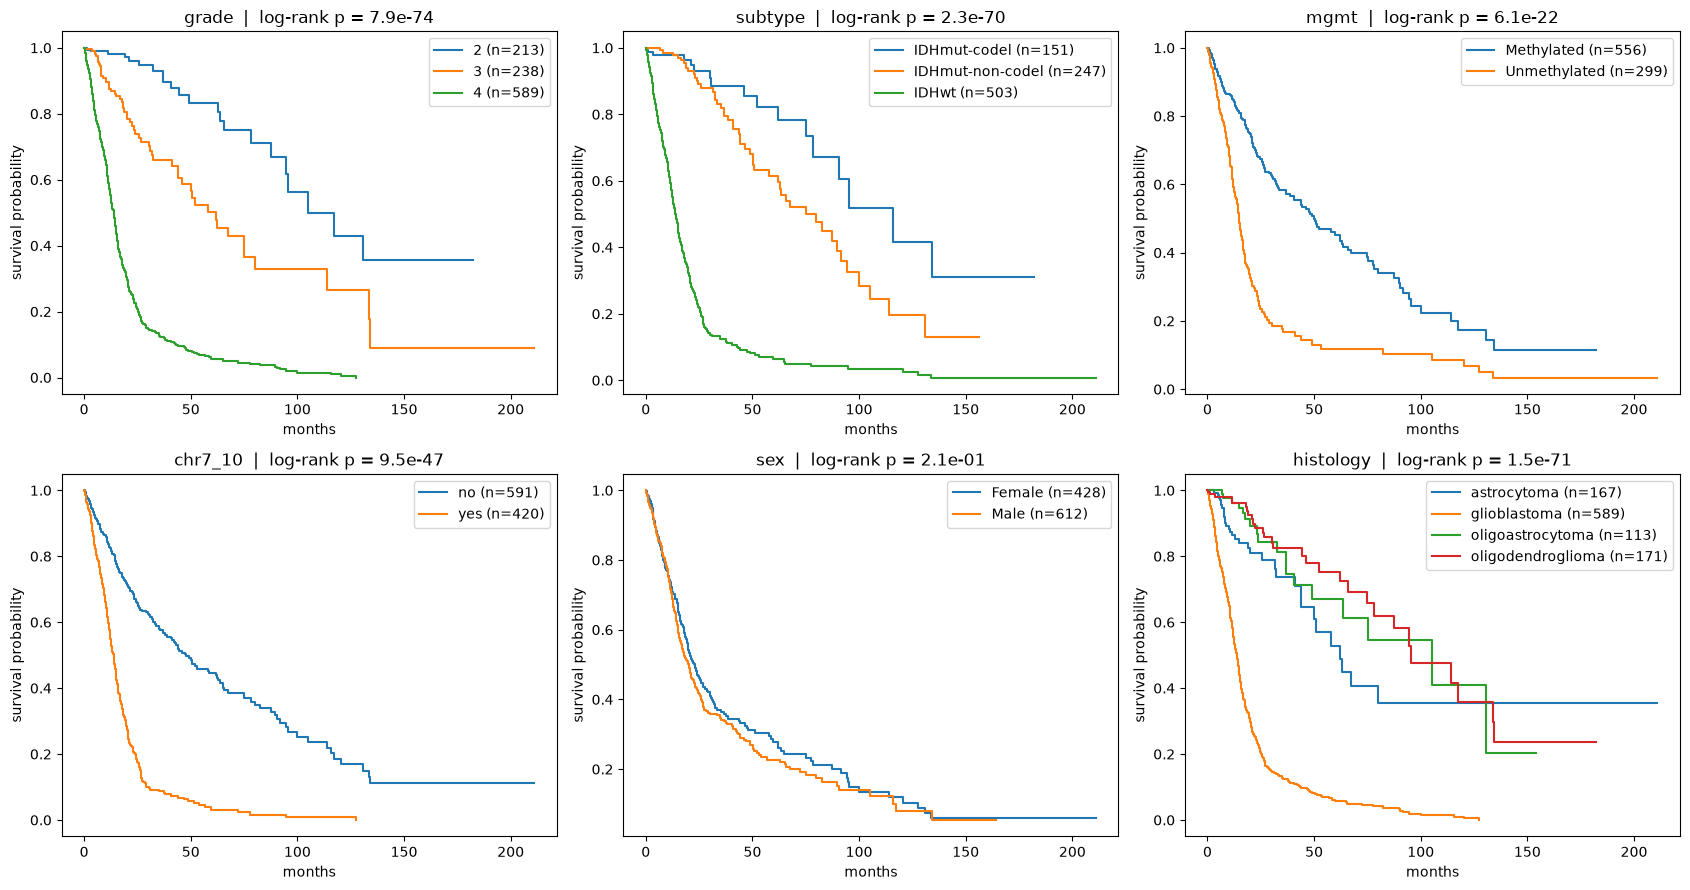

In [4]:
def km_by(col, data=df, ax=None):
    data = data.dropna(subset=[col])
    ax = ax or plt.subplots(figsize=(6, 4))[1]
    fitters = []
    for g, sub in data.groupby(col, observed=True):
        k = KaplanMeierFitter().fit(sub["time"], sub["event"], label=f"{g} (n={len(sub)})")
        k.plot_survival_function(ax=ax, ci_show=False)
        fitters.append(k)
    p = multivariate_logrank_test(data["time"], data[col], data["event"]).p_value
    ax.set_title(f"{col}  |  log-rank p = {p:.1e}")
    ax.set_xlabel("months"); ax.set_ylabel("survival probability")
    return fitters

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for col, ax in zip(["grade", "subtype", "mgmt", "chr7_10", "sex", "histology"], axes.ravel()):
    km_by(col, ax=ax)
plt.tight_layout()

Age is continuous — for a KM plot we bin it. (The Cox model below uses it as a number.)

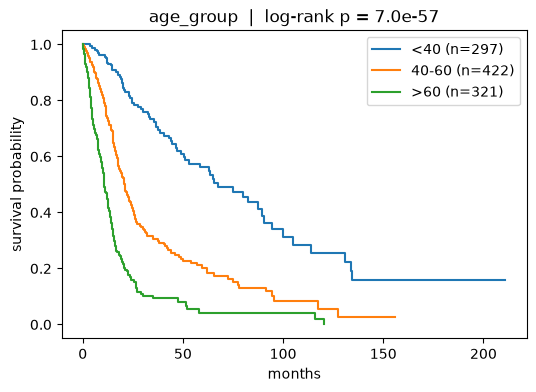

In [5]:
df["age_group"] = pd.cut(df["age"], [0, 40, 60, 100], labels=["<40", "40-60", ">60"])
km_by("age_group");

### Median survival per molecular subtype
This is the key result from the WHO 2016/2021 classification: IDH status matters more than histology.

In [6]:
rows = []
for g, sub in df.dropna(subset=["subtype"]).groupby("subtype"):
    k = KaplanMeierFitter().fit(sub["time"], sub["event"])
    rows.append({"subtype": g, "n": len(sub), "deaths": sub["event"].sum(),
                 "median_OS_months": k.median_survival_time_,
                 "5y_survival": float(k.survival_function_at_times(60).iloc[0])})
pd.DataFrame(rows).round(2)

,subtype,n,deaths,median_OS_months,5y_survival
0,IDHmut-codel,151,17,115.8,0.82
1,IDHmut-non-codel,247,50,75.1,0.61
2,IDHwt,503,340,14.0,0.06


## 4. Cox proportional hazards

* Hazard ratio (HR) > 1 → higher risk of death; < 1 → protective.
* Complete-case analysis for now (KPS and TERT have too many missing values, so they are left out).
* Reference levels: IDHwt, Unmethylated, Female.

In [7]:
features = ["age", "sex", "grade", "subtype", "mgmt"]
cox_df = df[features + ["time", "event"]].dropna()
print("patients used:", len(cox_df), "of", len(df))

X = pd.get_dummies(cox_df, columns=["sex", "subtype", "mgmt"], drop_first=False, dtype=float)
X = X.drop(columns=["sex_Female", "subtype_IDHwt", "mgmt_Unmethylated"])  # reference levels

cph = CoxPHFitter()
cph.fit(X, duration_col="time", event_col="event")
cph.print_summary(decimals=3, columns=["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"])

patients used: 793 of 1040


<lifelines.CoxPHFitter: fitted with 793 total observations, 481 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 793
number of events observed = 312
   partial log-likelihood = -1543.325
         time fit was run = 2026-10-02 16:33:48 UTC

---
                         exp(coef) exp(coef) lower 95% exp(coef) upper 95%       p
covariate                                                                         
age                          1.044               1.034               1.054 <0.0005
grade                        1.863               1.455               2.386 <0.0005
sex_Male                     1.496               1.176               1.904   0.001
subtype_IDHmut-codel         0.213               0.115               0.393 <0.0005
subtype_IDHmut-non-codel     0.441               0.284               0.686 <0.0005
mgmt_Methylated              0.949               0.742               1.214   0.676
---
Concordance = 0.834
Partial AIC = 3098.650
log-likelihood ratio test = 430.064 on 6 df
-log2(p) of ll-ratio test = 295.715

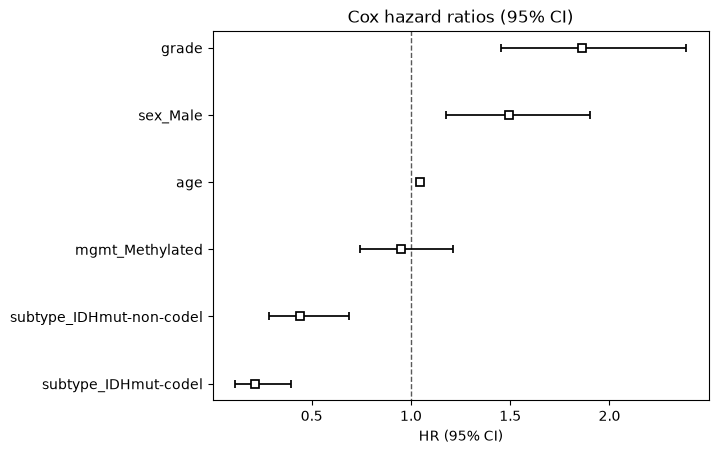

In [8]:
cph.plot(hazard_ratios=True)
plt.title("Cox hazard ratios (95% CI)");

### Check the proportional-hazards assumption
Cox assumes each HR is constant over time. If a variable violates it, the test below prints advice (e.g. stratify on it).

In [9]:
cph.check_assumptions(X, p_value_threshold=0.05, show_plots=False)

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'age' failed the non-proportional test: p-value is 0.0211.

   Advice 1: the functional form of the variable 'age' might be incorrect. That is, there may be
non-linear terms missing. The proportional hazard test used is very sensitive to incorrect
functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'age' using pd.cut, and then specify it in `strata=['age',
...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


2. Variable 'subtype_IDHmut-non-codel' failed the non-proportional test: p-value is 0.0038.

   Advice: with so few unique values (only 2), you can include `strata=['subtype_IDHmut-non-codel',
...]` in the call in `.fit`. See documentation in link [E] below.

---
[A]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html
[B] 

[]

## 5. Is the model useful? Concordance index (C-index)
0.5 = random, 1.0 = perfect ranking of who dies first. Here it is computed on the training data only (optimistic);
Step 3 will do a proper train/test split and compare against Random Survival Forest / DeepSurv.

In [10]:
print("C-index (train):", round(cph.concordance_index_, 3))

# Compare: age only vs. full model
cph_age = CoxPHFitter().fit(X[["age", "time", "event"]], "time", "event")
print("C-index age only:", round(cph_age.concordance_index_, 3))

C-index (train): 0.834
C-index age only: 0.783
